# GANisme — 01. Analyse exploratoire du catalogue Web Gallery of Art

**Objectif.** Décrire le catalogue complet (52 867 œuvres) *à partir des seules métadonnées*,
avant de télécharger la moindre image. Cette analyse doit permettre de :

1. isoler les peintures, seule forme demandée par l'énoncé ;
2. comprendre leur répartition (genres, écoles, artistes, époques, techniques, formats) ;
3. repérer les problèmes de qualité, les biais et les risques de fuite entre ensembles ;
4. **justifier les critères de sélection** du sous-ensemble téléchargé en phase 2 (cible : 5 000 à 10 000 images).

**Sauvegardes.** Les résultats sont écrits sur disque pour ne pas devoir relancer l'analyse :
- `data/processed/paintings_metadata.csv` : peintures + variables dérivées ;
- `reports/eda/summary.json` : chiffres clés ;
- `reports/eda/figures/*.png` : figures.

Les fonctions d'extraction (dates, dimensions, techniques…) sont dans `src/ganisme/eda.py` et testées
dans `tests/test_eda.py` ; le notebook ne fait que les appeler.

## 0. Configuration

In [1]:
import json
import platform
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Le notebook est dans notebooks/ : on remonte a la racine du projet pour importer src/ganisme.
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "ganisme").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from ganisme.data import load_csv
from ganisme.eda import add_features

RAW_CSV = ROOT / "data" / "raw" / "data.csv"
FEATURES_CSV = ROOT / "data" / "processed" / "paintings_metadata.csv"
REPORT_DIR = ROOT / "reports" / "eda"
FIG_DIR = REPORT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
FEATURES_CSV.parent.mkdir(parents=True, exist_ok=True)

SEED = 42

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight",
    "axes.titlesize": 13, "axes.labelsize": 11, "axes.grid": True,
    "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, GREY, ORANGE = "#2a6fdb", "#9aa5b1", "#e07b39"


def save_fig(fig, name):
    """Enregistre la figure et verifie que le fichier existe et n'est pas vide."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path)
    assert path.stat().st_size > 0, path
    return path


def barh(series, title, xlabel, ax=None, color=BLUE, pct_of=None):
    """Diagramme en barres horizontales, valeurs annotees (et % si pct_of est donne)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 0.32 * len(series) + 1.2))
    series = series.iloc[::-1]
    ax.barh(series.index.astype(str), series.values, color=color)
    for y, value in enumerate(series.values):
        label = f"{value:,}".replace(",", " ")
        if pct_of:
            label += f"  ({value / pct_of:.1%})"
        ax.text(value, y, " " + label, va="center", fontsize=9)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, series.max() * 1.25)
    ax.grid(axis="y", visible=False)
    return ax


print("Python", platform.python_version(), "| pandas", pd.__version__,
      "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)
print("Source :", RAW_CSV, "| existe :", RAW_CSV.exists())

Python 3.13.14 | pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2
Source : C:\Users\kahin\OneDrive\Documents\Projets\Ganisme\data\raw\data.csv | existe : True


## 1. Vue d'ensemble du catalogue

On charge le CSV brut avec `load_csv` (suppression des espaces dans les noms de colonnes et des lignes
entièrement vides). Tous les champs sont du **texte libre** : il faudra en extraire des valeurs numériques.

In [2]:
catalogue = load_csv(RAW_CSV)
print(f"{len(catalogue):,} lignes x {catalogue.shape[1]} colonnes")
catalogue.head(3)

52,867 lignes x 11 colonnes


,AUTHOR,BORN-DIED,TITLE,DATE,TECHNIQUE,LOCATION,URL,FORM,TYPE,SCHOOL,TIMEFRAME
0,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)",Venus and Adonis,1574-88,"Oil on canvas, 68 x 95 cm","Fogg Art Museum, Harvard University, Cambridge",https://www.wga.hu/html/a/aachen/adonis.html,painting,mythological,German,1601-1650
1,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)",Allegory,1598,"Oil on copper, 56 x 47 cm","Alte Pinakothek, Munich",https://www.wga.hu/html/a/aachen/allegory.html,painting,mythological,German,1601-1650
2,"AACHEN, Hans von","(b. 1552, Köln, d. 1615, Praha)","Allegory of Peace, Art and Abundance",1602,"Oil on canvas, 197 x 142 cm","The Hermitage, St. Petersburg",https://www.wga.hu/html/a/aachen/allegorz.html,painting,mythological,German,1601-1650


**Valeurs manquantes.** Le catalogue ne contient aucune cellule vide, mais les valeurs inconnues
sont codées par `"-"` (par exemple une date inconnue). On compte donc les deux.

In [3]:
quality = pd.DataFrame({
    "vides": catalogue.apply(lambda c: c.astype(str).str.strip().eq("").sum()),
    'codees "-"': catalogue.apply(lambda c: c.astype(str).str.strip().eq("-").sum()),
    "valeurs distinctes": catalogue.nunique(),
})
quality["% inconnues"] = (quality["vides"] + quality['codees "-"']) / len(catalogue) * 100
print("Lignes entierement dupliquees :", catalogue.duplicated().sum())
print("URL dupliquees               :", catalogue["URL"].duplicated().sum())
quality.round(1)

Lignes entierement dupliquees : 0
URL dupliquees               : 0


,vides,"codees ""-""",valeurs distinctes,% inconnues
AUTHOR,0,0,5767,0.0
BORN-DIED,0,0,8189,0.0
TITLE,0,0,31236,0.0
DATE,0,4800,5783,9.1
TECHNIQUE,0,1,23530,0.0
LOCATION,0,61,5550,0.1
URL,0,0,52867,0.0
FORM,0,0,13,0.0
TYPE,0,0,10,0.0
SCHOOL,0,0,26,0.0


L'URL est **unique pour chaque ligne** : elle sert d'identifiant stable pour relier une image à sa source
(manifeste de la phase 2). Il n'y a pas de doublon strict ; les quasi-doublons (vues de détail) sont
étudiés en section 8.

## 2. Formes d'art : isoler les peintures

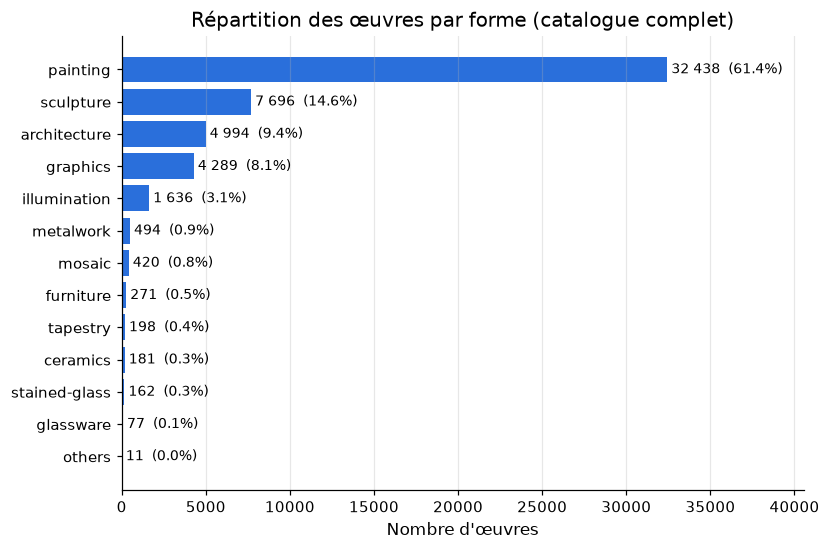

In [4]:
forms = catalogue["FORM"].value_counts()
ax = barh(forms, "Répartition des œuvres par forme (catalogue complet)", "Nombre d'œuvres",
          pct_of=len(catalogue))
save_fig(ax.figure, "01_forms")
plt.show()

In [5]:
paintings = add_features(catalogue[catalogue["FORM"] == "painting"]).reset_index(drop=True)
assert paintings["URL"].is_unique
print(f"Peintures : {len(paintings):,} ({len(paintings) / len(catalogue):.1%} du catalogue)")

Peintures : 32,438 (61.4% du catalogue)


Les peintures représentent 61 % du catalogue. Les autres formes (sculpture, architecture, gravures,
enluminures…) sont exclues comme le demande l'énoncé : elles introduiraient des photographies d'objets
3D et de bâtiments, visuellement très éloignées de l'objectif.

## 3. Qualité de l'extraction des variables dérivées

`add_features` ajoute : l'année (`year`), les dimensions en cm et le ratio largeur/hauteur, une famille
de technique, les années de naissance/décès de l'artiste, un indicateur de vue de détail, une clé
d'œuvre (`work_key`) et l'URL supposée de l'image. On vérifie le taux d'extraction de chacune plutôt
que de supposer que les expressions régulières fonctionnent.

In [6]:
coverage = paintings[["year", "height_cm", "aspect_ratio", "artist_born", "artist_died"]].notna().mean()
display(coverage.rename("taux d'extraction").to_frame().style.format("{:.1%}"))

unknown_date = paintings["DATE"].str.strip().eq("-")
unparsed = paintings["year"].isna() & ~unknown_date
print(f"Dates inconnues ('-')       : {unknown_date.sum():,}")
print(f"Dates non interpretees      : {unparsed.sum()} ->", paintings.loc[unparsed, "DATE"].tolist())
print(f"Annees hors [100, 1950]     : {((paintings.year < 100) | (paintings.year > 1950)).sum()}")

,taux d'extraction
year,88.0%
height_cm,69.6%
aspect_ratio,69.6%
artist_born,92.0%
artist_died,91.7%


Dates inconnues ('-')       : 3,887
Dates non interpretees      : 4 -> ['162628', '11757', '162123', '-.']
Annees hors [100, 1950]     : 0


- **Année** : toutes les dates renseignées sont interprétées, sauf 4 coquilles de la source (`162628`…).
  Les ~12 % restants sont des dates inconnues (`-`).
- **Dimensions** : absentes pour ~30 % des peintures, essentiellement des fresques (dimensions non
  pertinentes pour une peinture murale) et des panneaux sans mesures. Ce ne sont **pas** des dimensions
  d'image en pixels : la résolution réelle ne sera connue qu'au téléchargement.

## 4. Genres (`TYPE`)

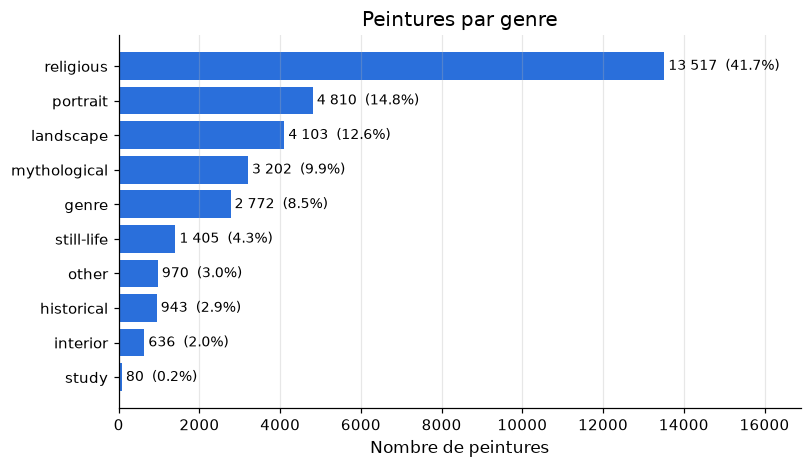

In [7]:
types = paintings["TYPE"].value_counts()
ax = barh(types, "Peintures par genre", "Nombre de peintures", pct_of=len(paintings))
save_fig(ax.figure, "02_types")
plt.show()

**Déséquilibre fort.** Les sujets religieux représentent ~42 % des peintures, presque trois fois plus
que les portraits, deuxième genre. Un GAN
entraîné sur un échantillon aléatoire produirait surtout des madones et des scènes bibliques, dans des
tons dorés/bruns. Les natures mortes, intérieurs et paysages sont minoritaires. La catégorie `other`
est fourre-tout et peu informative.

→ Conséquence pour la phase 2 : un **échantillonnage stratifié par genre** (avec plafond par genre)
sera nécessaire si l'on veut de la diversité de compositions.

## 5. Écoles et artistes

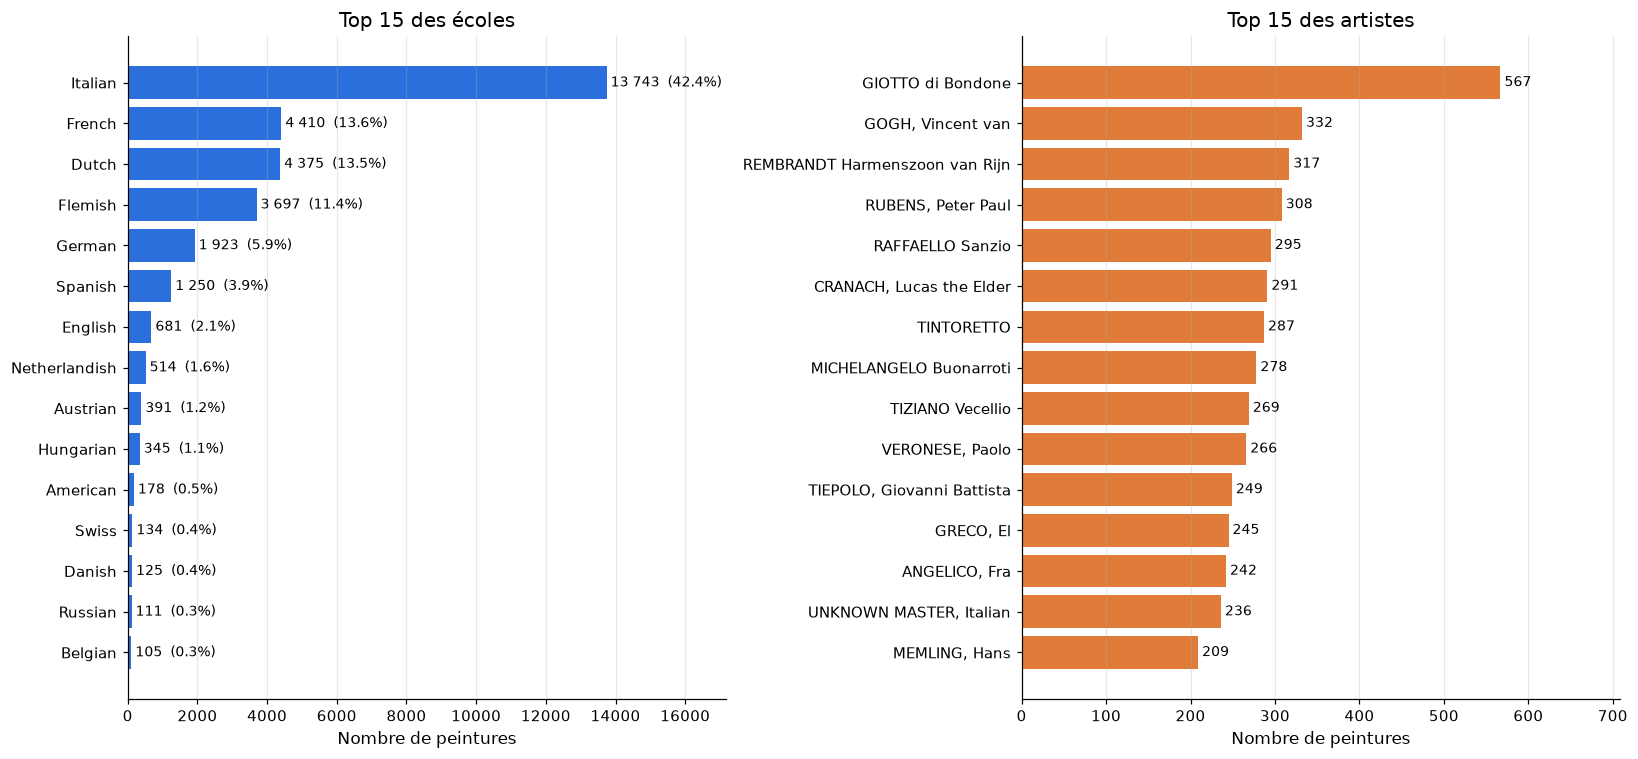

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
barh(paintings["SCHOOL"].value_counts().head(15), "Top 15 des écoles", "Nombre de peintures",
     ax=axes[0], pct_of=len(paintings))
barh(paintings["AUTHOR"].value_counts().head(15), "Top 15 des artistes", "Nombre de peintures",
     ax=axes[1], color=ORANGE)
fig.tight_layout()
save_fig(fig, "03_schools_artists")
plt.show()

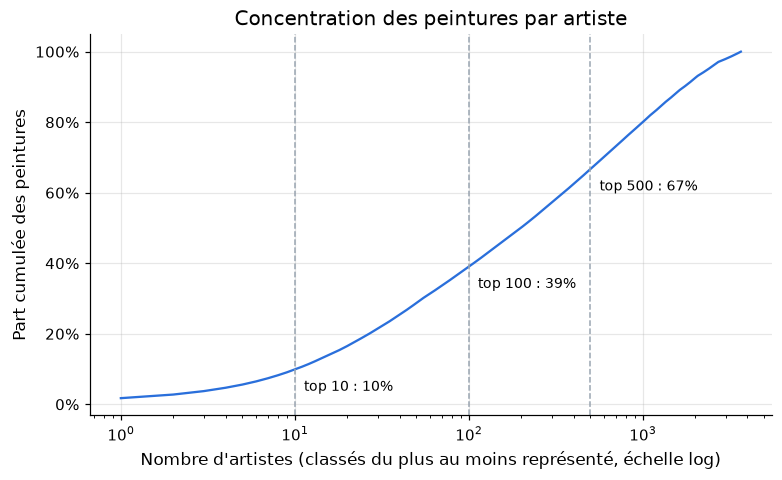

3,663 artistes ; mediane 3 peinture(s) par artiste ; 962 artistes n'ont qu'une peinture
Auteurs anonymes (UNKNOWN) : 618


In [9]:
per_artist = paintings["AUTHOR"].value_counts()
cumulative = per_artist.cumsum() / per_artist.sum()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(np.arange(1, len(cumulative) + 1), cumulative.values, color=BLUE)
for n in (10, 100, 500):
    ax.axvline(n, color=GREY, ls="--", lw=1)
    ax.annotate(f"top {n} : {cumulative.iloc[n - 1]:.0%}", (n, cumulative.iloc[n - 1]),
                xytext=(6, -14), textcoords="offset points", fontsize=9)
ax.set_xscale("log")
ax.set_title("Concentration des peintures par artiste")
ax.set_xlabel("Nombre d'artistes (classés du plus au moins représenté, échelle log)")
ax.set_ylabel("Part cumulée des peintures")
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
save_fig(fig, "04_artist_concentration")
plt.show()

print(f"{len(per_artist):,} artistes ; mediane {per_artist.median():.0f} peinture(s) par artiste ;"
      f" {(per_artist == 1).sum():,} artistes n'ont qu'une peinture")
print(f"Auteurs anonymes (UNKNOWN) : {paintings['AUTHOR'].str.contains('UNKNOWN', case=False).sum():,}")

- L'**école italienne** pèse ~42 % des peintures ; avec les écoles française, hollandaise et flamande,
  on dépasse 80 % : le corpus est très **européen de l'Ouest**.
- La concentration par artiste est **modérée** : les 10 premiers artistes ne pèsent que ~10 % des
  peintures, les 100 premiers ~39 %, avec une longue traîne (médiane : 3 peintures par artiste).
  Giotto arrive en tête surtout grâce à ses cycles de fresques détaillés vue par vue.
- → Un **plafond de peintures par artiste** reste utile, à titre de garde-fou : il empêche
  qu'un tirage aléatoire sur-échantillonne un artiste et favorise la mémorisation de ses œuvres.

## 6. Époques

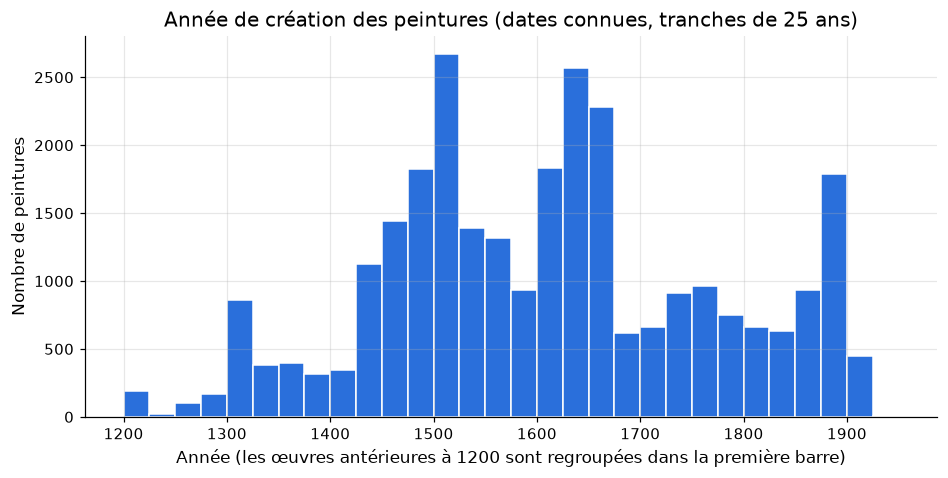

Annee connue pour 88.0% des peintures ; mediane 1611 ; avant 1200 : 175


In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.arange(1200, 1951, 25)
ax.hist(paintings["year"].dropna().clip(1200, 1949), bins=bins, color=BLUE, edgecolor="white")
ax.set_title("Année de création des peintures (dates connues, tranches de 25 ans)")
ax.set_xlabel("Année (les œuvres antérieures à 1200 sont regroupées dans la première barre)")
ax.set_ylabel("Nombre de peintures")
save_fig(fig, "05_years")
plt.show()

print(f"Annee connue pour {paintings['year'].notna().mean():.1%} des peintures ;"
      f" mediane {paintings['year'].median():.0f} ; avant 1200 : {(paintings['year'] < 1200).sum()}")

Le catalogue couvre surtout **1300-1900**, avec trois pics : la Renaissance (1475-1525), le XVIIe siècle (baroque, âge d'or hollandais) et les années 1880 (impressionnisme, Van Gogh).
L'art moderne (XXe siècle) est quasi absent : le catalogue s'arrête vers 1900, d'où l'idée optionnelle
de l'énoncé d'ajouter un jeu de peintures abstraites.

**Incohérence repérée : `TIMEFRAME` ne date pas toujours l'œuvre.** Par exemple *Venus and Adonis* de
Hans von Aachen (1574-88) est classée `1601-1650`. On mesure à quelle fréquence l'année de l'œuvre
tombe dans sa tranche `TIMEFRAME`, et on teste l'hypothèse d'une tranche fondée sur le décès de l'artiste :

In [11]:
bounds = paintings["TIMEFRAME"].str.extract(r"(\d{4})-(\d{4})").astype(float)
dated = paintings["year"].notna()
inside = paintings["year"].between(bounds[0], bounds[1])
print(f"Annee dans TIMEFRAME : {inside[dated].mean():.1%} des peintures datees")

death_bounds = paintings["artist_died"].between(bounds[0], bounds[1])
print(f"Deces de l'artiste dans TIMEFRAME : "
      f"{death_bounds[paintings['artist_died'].notna()].mean():.1%} des peintures (artiste date)")

Annee dans TIMEFRAME : 81.8% des peintures datees
Deces de l'artiste dans TIMEFRAME : 46.8% des peintures (artiste date)


`TIMEFRAME` est cohérent avec la date de l'œuvre dans ~82 % des cas ; l'hypothèse « tranche du décès
de l'artiste » ne tient pas (moins d'un cas sur deux). Les ~18 % d'écarts sont en général d'une seule
tranche. La règle exacte utilisée par la source n'est pas documentée : pour toute analyse temporelle, on
utilise donc **`year`** (extrait de `DATE`), et `TIMEFRAME` seulement en repli quand la date de
l'œuvre est inconnue (12 % des peintures).

## 7. Techniques et formats

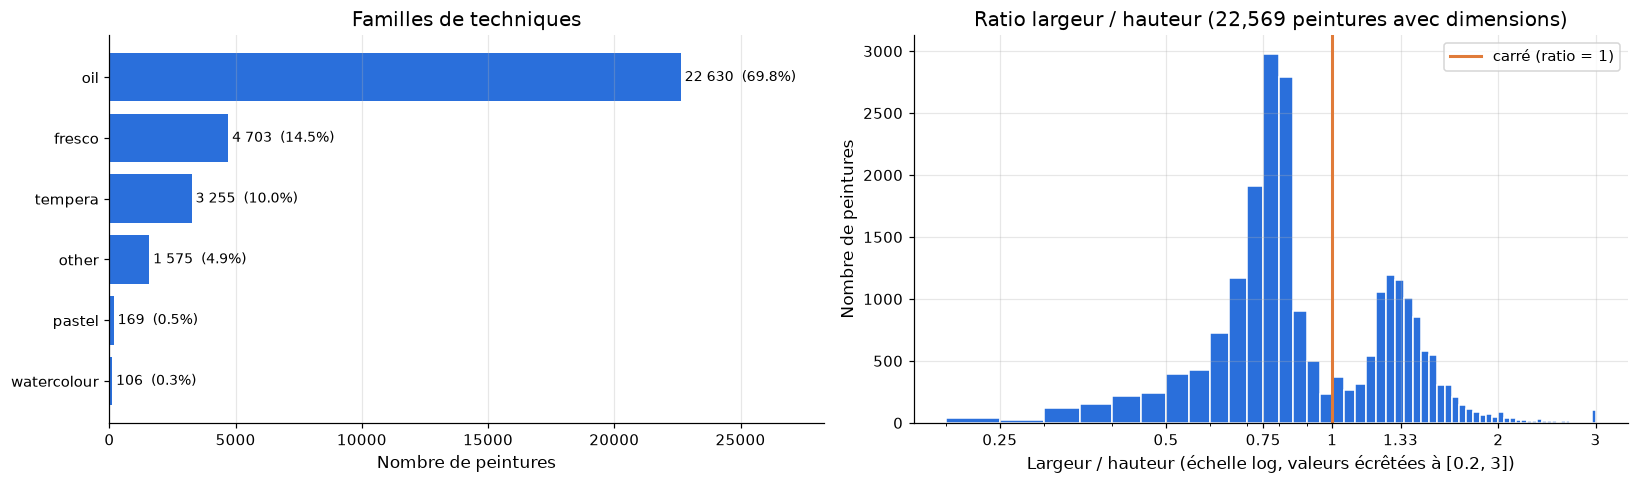

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
barh(paintings["technique_family"].value_counts(), "Familles de techniques", "Nombre de peintures",
     ax=axes[0], pct_of=len(paintings))

ratio = paintings["aspect_ratio"].dropna()
axes[1].hist(ratio.clip(0.2, 3), bins=np.linspace(0.2, 3, 57), color=BLUE, edgecolor="white")
axes[1].axvline(1, color=ORANGE, lw=2, label="carré (ratio = 1)")
axes[1].set_xscale("log")
axes[1].set_xticks([0.25, 0.5, 0.75, 1, 1.33, 2, 3], ["0.25", "0.5", "0.75", "1", "1.33", "2", "3"])
axes[1].xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())  # evite les etiquettes log superposees
axes[1].set_title(f"Ratio largeur / hauteur ({len(ratio):,} peintures avec dimensions)")
axes[1].set_xlabel("Largeur / hauteur (échelle log, valeurs écrêtées à [0.2, 3])")
axes[1].set_ylabel("Nombre de peintures")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "06_techniques_ratios")
plt.show()

In [13]:
orientation = pd.cut(ratio, [0, 0.8, 1.25, np.inf], labels=["portrait (< 0.8)", "~carré", "paysage (> 1.25)"])
display(orientation.value_counts(normalize=True).rename("part").to_frame().style.format("{:.1%}"))
lost = (1 - np.minimum(ratio, 1 / ratio))
print(f"Surface perdue par un recadrage central carré : mediane {lost.median():.0%},"
      f" 90e centile {lost.quantile(0.9):.0%}")
print(f"Ratios extremes (< 0.4 ou > 2.5) : {((ratio < 0.4) | (ratio > 2.5)).mean():.1%}")

,part
aspect_ratio,
portrait (< 0.8),38.0%
paysage (> 1.25),31.5%
~carré,30.5%


Surface perdue par un recadrage central carré : mediane 24%, 90e centile 43%
Ratios extremes (< 0.4 ou > 2.5) : 2.3%


- L'**huile** domine (~70 %) ; les **fresques** (~15 %) sont souvent photographiées in situ (murs,
  plafonds, voûtes, éclairage inégal) et les **temperas sur panneau** à fond d'or ont une esthétique
  très particulière.
- Les GAN usuels (DCGAN) génèrent des images **carrées**. Le format médian est plutôt vertical
  (ratio ≈ 0.85) : un recadrage central carré perd en médiane un quart de la surface, bien plus pour les
  formats extrêmes (polyptyques, frises, prédelles).
- → En phase 2 : recadrage central carré puis redimensionnement, et **exclusion des ratios extrêmes**
  quand ils sont connus, pour ne pas apprendre des images tronquées sans composition. Le ratio réel
  sera recontrôlé sur les pixels après téléchargement.

## 8. Vues de détail et quasi-doublons : risque de fuite

Le catalogue contient de nombreuses vues partielles d'une même œuvre (`... (detail)`), ainsi que des
séries d'une même scène. Si une œuvre et son détail se retrouvent l'une dans le jeu d'entraînement,
l'autre dans le jeu d'évaluation, les métriques (FID, KID, recherche de mémorisation) sont faussées.

In [14]:
group_sizes = paintings.groupby("work_key").size()
print(f"Vues de detail                       : {paintings['is_detail'].sum():,} "
      f"({paintings['is_detail'].mean():.1%})")
print(f"Oeuvres distinctes (work_key)        : {len(group_sizes):,}")
print(f"Peintures dans un groupe de taille>1 : {group_sizes[group_sizes > 1].sum():,}")
print("Plus grands groupes :")
display(group_sizes.sort_values(ascending=False).head(8).rename("lignes").to_frame())

Vues de detail                       : 4,987 (15.4%)
Oeuvres distinctes (work_key)        : 25,541
Peintures dans un groupe de taille>1 : 10,501
Plus grands groupes :


,lignes
work_key,
GIOTTO di Bondone|last judgment,37
MICHELANGELO Buonarroti|last judgment,31
"BRUEGEL, Pieter the Elder|the tower of babel",24
"BRUEGEL, Pieter the Elder|children's games",23
MICHELANGELO Buonarroti|ignudo,23
"BOSCH, Hieronymus|triptych of garden of earthly delights",23
"WEYDEN, Rogier van der|the last judgment",22
"CAVALLINI, Pietro|last judgment",20


Les plus grands groupes portent des titres génériques (cycles de fresques, « Decoration »…) : la clé
d'œuvre est donc **prudente** (elle regroupe parfois des vues différentes d'un même ensemble), ce qui
est souhaitable pour éviter les fuites.

→ En phase 2 : **exclure les vues de détail** (elles recadrent une partie d'une œuvre, avec une
composition non représentative) et faire tout découpage entraînement/évaluation **par `work_key`**,
jamais par ligne.

## 9. Croisements : genre × époque et genre × technique

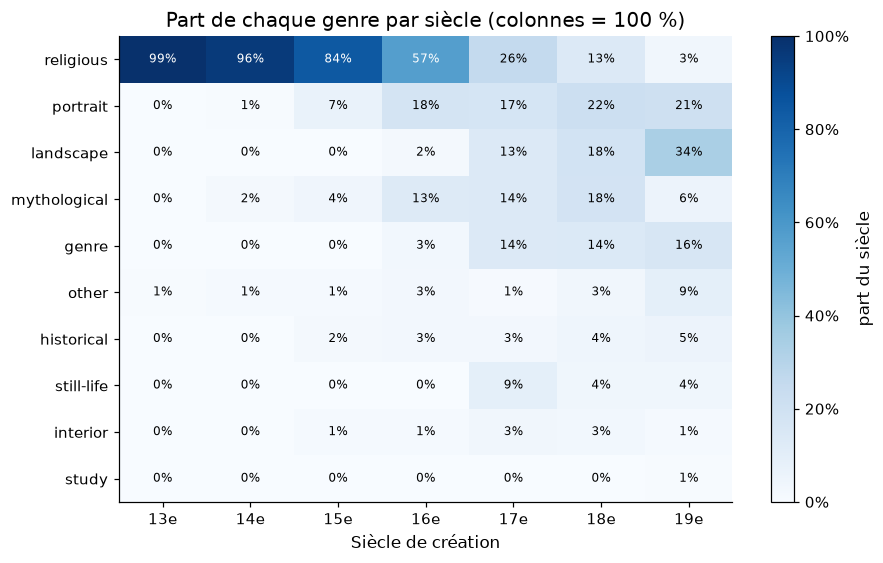

In [15]:
century = (paintings["year"] // 100 + 1).astype("Int64")
table = pd.crosstab(paintings["TYPE"], century, normalize="columns")
table = table.loc[:, [c for c in table.columns if 13 <= c <= 19]]
table.columns = [f"{c}e" for c in table.columns]
table = table.loc[table.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(table.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(table.shape[1]), table.columns)
ax.set_yticks(range(table.shape[0]), table.index)
for (i, j), v in np.ndenumerate(table.values):
    ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > 0.55 else "black")
ax.set_title("Part de chaque genre par siècle (colonnes = 100 %)")
ax.set_xlabel("Siècle de création")
ax.grid(False)
fig.colorbar(im, ax=ax, format=matplotlib.ticker.PercentFormatter(1.0), label="part du siècle")
save_fig(fig, "07_type_by_century")
plt.show()

In [16]:
display(pd.crosstab(paintings["TYPE"], paintings["technique_family"], margins=True, margins_name="total"))

technique_family,fresco,oil,other,pastel,tempera,watercolour,total
TYPE,,,,,,,
genre,62,2633,23,28,13,13,2772
historical,132,714,20,0,73,4,943
interior,254,353,23,0,2,4,636
landscape,33,3998,32,5,13,22,4103
mythological,839,2149,87,10,105,12,3202
other,232,592,78,26,32,10,970
portrait,56,4289,172,95,170,28,4810
religious,3093,6439,1130,1,2844,10,13517
still-life,2,1391,6,2,2,2,1405


Le genre est fortement lié à l'époque : le religieux domine jusqu'au XVIe siècle, puis les portraits,
paysages, scènes de genre et natures mortes apparaissent aux XVIIe-XIXe siècles. Stratifier par genre
rééquilibre donc aussi, en partie, les époques. Les fresques sont religieuses aux deux tiers.

## 10. Institutions, sources et conditions d'utilisation

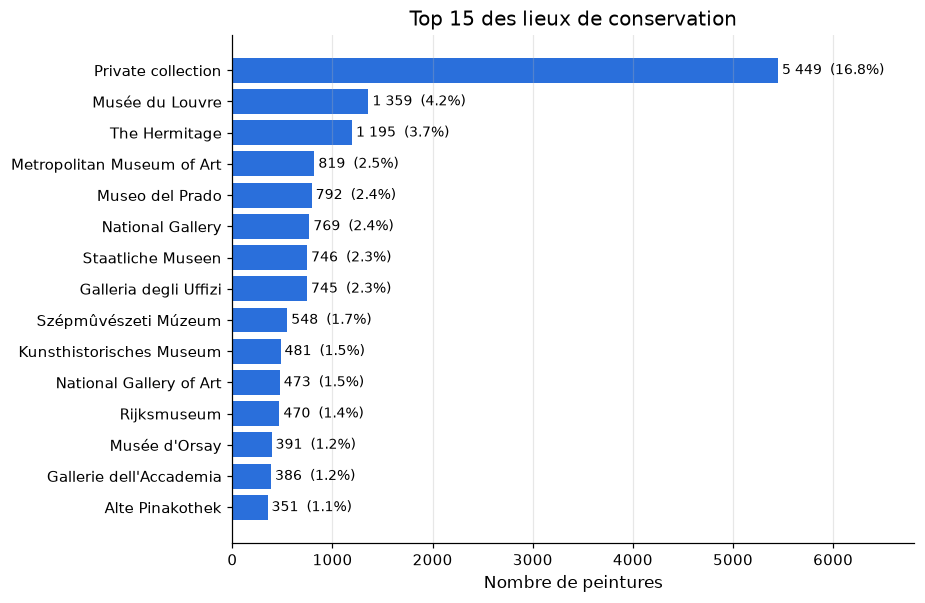

1,874 lieux distincts ; 'Private collection' : 5,449


In [17]:
museum = paintings["LOCATION"].str.split(",").str[0].str.strip()
ax = barh(museum.value_counts().head(15), "Top 15 des lieux de conservation", "Nombre de peintures",
          pct_of=len(paintings))
save_fig(ax.figure, "08_locations")
plt.show()
print(f"{museum.nunique():,} lieux distincts ; 'Private collection' : "
      f"{museum.str.contains('Private collection', case=False).sum():,}")

- Les images proviennent toutes d'une **source unique** (wga.hu) : la qualité de numérisation (couleurs,
  cadrages, photos anciennes) est donc homogène dans sa méthode mais variable selon les œuvres. Les
  grands musées (Louvre, Offices, National Gallery…) sont surreprésentés.
- **URL des images** : la page `.../html/a/aachen/adonis.html` correspond à l'image
  `.../art/a/aachen/adonis.jpg` (fonction `image_url`). Une requête de contrôle sur un exemple a renvoyé
  `HTTP 200` et `image/jpeg` ; la règle sera **vérifiée sur tout l'échantillon** au téléchargement
  (statut `failed` sinon).
- **Licence** : la Web Gallery of Art autorise un usage éducatif et personnel de ses images. Le projet
  (pédagogique) s'y inscrit ; les images téléchargées ne doivent pas être redistribuées dans le dépôt
  Git (déjà exclu par `.gitignore`).

## 11. Synthèse et proposition de sélection pour la phase 2

In [18]:
mask_detail = ~paintings["is_detail"]
mask_fresco = paintings["technique_family"] != "fresco"
r = paintings["aspect_ratio"]
mask_ratio = r.isna() | r.between(0.5, 2.0)
candidates = paintings[mask_detail & mask_fresco & mask_ratio]

funnel = pd.Series({
    "peintures": len(paintings),
    "sans vues de détail": int(mask_detail.sum()),
    "+ sans fresques": int((mask_detail & mask_fresco).sum()),
    "+ ratio connu dans [0.5, 2] ou inconnu": len(candidates),
})
display(funnel.rename("lignes restantes").to_frame())
display(candidates["TYPE"].value_counts().rename("candidats").to_frame().T)

,lignes restantes
peintures,32438
sans vues de détail,27451
+ sans fresques,24379
"+ ratio connu dans [0.5, 2] ou inconnu",23228


TYPE,religious,portrait,landscape,genre,mythological,still-life,other,historical,interior,study
candidats,7599,4457,3775,2396,1975,1334,641,621,353,77


In [19]:
summary = {
    "source": str(RAW_CSV.relative_to(ROOT)),
    "n_catalogue": len(catalogue),
    "n_paintings": len(paintings),
    "n_artists": int(paintings["AUTHOR"].nunique()),
    "n_works": int(paintings["work_key"].nunique()),
    "n_detail_views": int(paintings["is_detail"].sum()),
    "share_known_year": round(float(paintings["year"].notna().mean()), 4),
    "share_with_dimensions": round(float(paintings["aspect_ratio"].notna().mean()), 4),
    "median_aspect_ratio": round(float(ratio.median()), 3),
    "share_year_inside_timeframe": round(float(inside[dated].mean()), 4),
    "types": paintings["TYPE"].value_counts().to_dict(),
    "schools_top10": paintings["SCHOOL"].value_counts().head(10).to_dict(),
    "techniques": paintings["technique_family"].value_counts().to_dict(),
    "selection_funnel": {k: int(v) for k, v in funnel.items()},
    "candidate_types": candidates["TYPE"].value_counts().to_dict(),
}
(REPORT_DIR / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
paintings.to_csv(FEATURES_CSV, index=False)

# Controle de la sauvegarde : relecture et comparaison.
reloaded = pd.read_csv(FEATURES_CSV)
assert len(reloaded) == len(paintings) and list(reloaded.columns) == list(paintings.columns)
print("Sauvegarde OK :", FEATURES_CSV.relative_to(ROOT), reloaded.shape)
print("Figures      :", sorted(p.name for p in FIG_DIR.glob("*.png")))

Sauvegarde OK : data\processed\paintings_metadata.csv (32438, 21)
Figures      : ['01_forms.png', '02_types.png', '03_schools_artists.png', '04_artist_concentration.png', '05_years.png', '06_techniques_ratios.png', '07_type_by_century.png', '08_locations.png']


### Constats principaux

| Constat | Conséquence pour la phase 2 |
| --- | --- |
| 32 438 peintures, URL uniques, aucune cellule vide (inconnues codées `-`) | URL = identifiant du manifeste |
| ~42 % de sujets religieux, `other` fourre-tout | échantillonnage **stratifié par genre** avec plafond |
| École italienne ~42 %, quelques artistes très présents | **plafond par artiste** |
| `TIMEFRAME` incohérent avec la date dans ~18 % des cas | utiliser `year` (extrait de `DATE`) |
| ~15 % de vues de détail, séries d'une même œuvre | **exclure les détails**, découper par `work_key` |
| Fresques (~15 %) : photos in situ, formats et éclairages hétérogènes | **exclure** pour la baseline |
| Formats majoritairement non carrés, quelques ratios extrêmes | recadrage central carré, exclure ratios hors [0.5, 2] |
| Dimensions en cm ≠ résolution en pixels | contrôler la résolution réelle au téléchargement |

### Proposition (à valider avant téléchargement)

Tirer **~8 000 peintures** parmi les candidats ci-dessus, avec une graine fixe :
- plafond par genre : le religieux limité à ~25 % de l'échantillon (33 % parmi les candidats), en conservant
  intégralement les genres rares ;
- plafond de ~30 peintures par artiste ;
- images redimensionnées en **64×64** pour la baseline DCGAN (128×128 archivées si le coût le permet).

Ces choix sont des **hypothèses de travail** : ils seront réévalués après inspection visuelle d'un
échantillon d'images téléchargées.